# **Gaia DR3 Variable Stars:**  Modeling

## Imports and Configuration

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

for path in (root / "src", root):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from gaia_variable_stars.config import (
    CLASSES, CLEAN_FILE, CV_FILE, FEATURE_FILE, FIGURES_ROOT, FOLDS,
    MODEL_FILE, MODELS_ROOT, PRED_FILE, RANK_FILE, SEED, SOURCE_FILE,
)

FE_FEATURE_FILE = FEATURE_FILE.with_name("gaia_features_fe.csv")
FE_VALIDATION_FILE = FEATURE_FILE.with_name("gaia_period_validation_fe.csv")
FE_ORACLE_FILE = FEATURE_FILE.with_name("gaia_features_fe_oracle.csv")
LABEL_FILE = FEATURE_FILE.with_name("gaia_label_confidence.csv")

EXTRA_ROOT = MODELS_ROOT / "gaia_classification"
PLOT_ROOT = FIGURES_ROOT / "gaia_classification"

for path in (MODELS_ROOT, EXTRA_ROOT, PLOT_ROOT):
    path.mkdir(parents=True, exist_ok=True)

PRIMARY = "RF"
REPEATS = 5
BOOTSTRAPS = 1500
PERM_REPEATS = 5
MIN_CELL = 10

## Features

In [2]:
GROUPS = {
    "period": [
        "log_period", "power", "half_power", "double_power",
        "half_power_ratio", "double_power_ratio", "fourier_amp", "fourier_ratio",
    ],
    "shape": [
        "magnitude_std", "magnitude_skew", "magnitude_kurt",
        "magnitude_mad", "amplitude", "beyond_1sigma_fraction",
    ],
    "timescale": [
        "von_neumann_eta", "stetson_j", "sf_short",
        "sf_long", "sf_ratio", "max_visit_slope",
    ],
    "color": ["bp_rp_color"],
    "brightness_noise": ["magnitude_mean", "median_error", "amplitude_ratio"],
    "sampling": [
        "n_epochs", "time_span", "median_gap", "short_gap_fraction",
        "n_visits", "epochs_per_visit", "median_visit_gap", "visit_gap_cv",
    ],
}

MAIN_GROUPS = [name for name in GROUPS if name != "sampling"]

def columns(names):
    return [col for name in names for col in GROUPS[name]]

BASE_FEATURES = columns(MAIN_GROUPS)
ALL_FEATURES = columns(GROUPS)

In [3]:
B_STATS = ["magnitude_std", "magnitude_mad", "magnitude_skew", "magnitude_kurt", "amplitude"]

FOURIER_EXTRA = ["R31_naive", "phi21_naive", "phi31_naive"]

C_TIME = B_STATS + GROUPS["period"] + FOURIER_EXTRA

In [4]:
FEATURE_SETS = {
    "full": BASE_FEATURES,
    "oracle": BASE_FEATURES,
    "period_free": columns([name for name in MAIN_GROUPS if name != "period"]),
    "A_metadata": ["bp_rp_color", "magnitude_mean"],
    "B_stats": B_STATS,
    "C_timedomain": C_TIME,
    "D_full": C_TIME + ["bp_rp_color"],
}

for col in ["magnitude_std", "amplitude", "fourier_amp"]:
    FEATURE_SETS[f"drop_{col}"] = [c for c in BASE_FEATURES if c != col]

FAMILY_DROPS = ["drop_color", "drop_brightness_noise", "drop_timescale"]

for family in ["color", "brightness_noise", "timescale"]:
    FEATURE_SETS[f"drop_{family}"] = columns([name for name in MAIN_GROUPS if name != family])

## Data

In [5]:
sources = pd.read_csv(SOURCE_FILE)
features = pd.read_csv(FE_FEATURE_FILE)
validation = pd.read_csv(FE_VALIDATION_FILE)
oracle = pd.read_csv(FE_ORACLE_FILE)
labels = pd.read_csv(LABEL_FILE)

feature_cols = columns(["period", "shape", "timescale", "brightness_noise"]) + FOURIER_EXTRA

stars = (
    sources[["source_id", "class_name", "bp_rp_color", "g_mean_magnitude", "gaia_period"]]
    .merge(
        validation[["source_id", "period_eligible", "period_status", "sky_cell", *GROUPS["sampling"]]],
        on="source_id", how="left", validate="one_to_one",
    )
    .merge(features[["source_id", *feature_cols]], on="source_id", how="left", validate="one_to_one")
    .merge(
        labels[["source_id", "matches_general_class", "best_class_score"]],
        on="source_id", how="left", validate="one_to_one",
    )
    .sort_values("source_id")
    .reset_index(drop=True)
)

if len(stars) != 2000 or stars["sky_cell"].isna().any():
    raise ValueError("Expected 2,000 stars with period-validation and sky-cell data.")

excluded = len(stars) - len(features)
stars = stars.loc[stars["source_id"].isin(features["source_id"])].reset_index(drop=True)
assert len(stars) == len(features)

stars["matches_general_class"] = stars["matches_general_class"].astype(bool)

numeric = list(dict.fromkeys([*ALL_FEATURES, *FOURIER_EXTRA, "g_mean_magnitude", "gaia_period"]))
stars[numeric] = stars[numeric].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
stars["eligible"] = stars["period_eligible"].fillna(False).astype(bool)

oracle_stars = stars.copy()
reference = oracle.set_index("source_id").reindex(stars.loc[stars["eligible"], "source_id"])

if reference["log_period"].isna().any():
    raise ValueError("Oracle periods are missing for eligible stars.")

oracle_stars.loc[stars["eligible"], GROUPS["period"]] = reference[GROUPS["period"]].to_numpy()

print("Total stars:", len(stars))
print("Excluded before modeling (not searchable):", excluded)

Total stars: 1978
Excluded before modeling (not searchable): 22


In [6]:
STATUSES = ["exact", "half", "double", "mismatch", "ineligible"]

display(
    pd.crosstab(stars["class_name"], stars["period_status"])
    .reindex(index=CLASSES, columns=STATUSES, fill_value=0)
)

period_status,exact,half,double,mismatch,ineligible
class_name,,,,,
RR Lyrae,392,1,0,85,0
Cepheid,495,0,0,5,0
Eclipsing Binary,12,366,2,120,0
Long-Period Variable,269,0,0,132,99


## Cross-Validation

In [7]:
y = stars["class_name"].to_numpy()
sky = stars["sky_cell"].to_numpy()

splits = []
folds = np.zeros((REPEATS, len(stars)), dtype=np.uint8)

for repeat in range(REPEATS):
    cv = StratifiedGroupKFold(
        n_splits=FOLDS, shuffle=True, random_state=SEED + 101 * repeat
    )

    for fold, (train, test) in enumerate(cv.split(stars, y, sky), start=1):
        if len(np.unique(y[train])) != len(CLASSES):
            raise ValueError(f"Training class missing in repeat {repeat + 1}, fold {fold}.")

        folds[repeat, test] = fold
        splits.append((repeat, fold, train, test))

if (folds == 0).any():
    raise ValueError("Some stars have no out-of-fold prediction assignment.")

print("Sky cells:", stars["sky_cell"].nunique())
print("Folds:", FOLDS)
print("Repeats:", REPEATS)

Sky cells: 167
Folds: 5
Repeats: 5


In [8]:
fold_counts = pd.crosstab(stars["class_name"], folds[0]).reindex(CLASSES)
fold_counts.columns = [f"test_fold_{c}" for c in fold_counts.columns]
fold_counts.insert(0, "total", fold_counts.sum(axis=1))
fold_counts.to_csv(EXTRA_ROOT / "fold_counts.csv")
display(fold_counts)

,total,test_fold_1,test_fold_2,test_fold_3,test_fold_4,test_fold_5
class_name,,,,,,
RR Lyrae,478,95,95,96,96,96
Cepheid,500,118,95,95,96,96
Eclipsing Binary,500,80,126,127,87,80
Long-Period Variable,500,156,103,76,82,83


## Models

In [9]:
def make_model(name, variant):
    if name == "Dummy":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("model", DummyClassifier(strategy="stratified", random_state=SEED)),
        ])

    if name == "LR":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=5000, random_state=SEED)),
        ])

    if name == "RF":
        return Pipeline([
            ("imputer", SimpleImputer(
                strategy="median", add_indicator=True, keep_empty_features=True
            )),
            ("model", RandomForestClassifier(
                n_estimators=250, min_samples_leaf=2,
                max_features="sqrt", random_state=SEED, n_jobs=-1
            )),
        ])

    model = HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.05, min_samples_leaf=15,
        l2_regularization=1.0, random_state=SEED,
    )
    return Pipeline([
        ("flags", FeatureUnion([
            ("values", FunctionTransformer()),
            ("missing", MissingIndicator(features="all", sparse=False)),
        ])),
        ("model", model),
    ])

In [10]:
importance_rows = []
family_rows = []


def predict_oof(name, variant):
    cols = FEATURE_SETS[variant]
    data = oracle_stars if variant == "oracle" else stars
    result = np.full((REPEATS, len(stars)), None, dtype=object)

    for repeat, fold, train, test in splits:
        model = make_model(name, variant)
        model.fit(data.iloc[train][cols], y[train])
        result[repeat, test] = model.predict(data.iloc[test][cols])

        if name == PRIMARY and variant == "full" and repeat == 0:
            score = permutation_importance(
                model, data.iloc[test][cols], y[test],
                scoring=lambda fit, x, truth: f1_score(
                    truth, fit.predict(x), labels=CLASSES, average="macro", zero_division=0
                ),
                n_repeats=PERM_REPEATS, random_state=SEED + fold, n_jobs=1,
            )
            for col, decrease in zip(cols, score.importances_mean):
                importance_rows.append({"fold": fold, "feature": col, "macro_f1_drop": float(decrease)})

            x_test = data.iloc[test][cols]
            rng = np.random.default_rng(SEED + fold)
            base = f1_score(y[test], model.predict(x_test), labels=CLASSES,
                            average="macro", zero_division=0)
            for family, members in GROUPS.items():
                present = [c for c in members if c in cols]
                if not present:
                    continue
                drops = []
                for _ in range(PERM_REPEATS):
                    shuffled = x_test.copy()
                    shuffled[present] = x_test[present].to_numpy()[rng.permutation(len(x_test))]
                    drops.append(base - f1_score(
                        y[test], model.predict(shuffled), labels=CLASSES,
                        average="macro", zero_division=0))
                family_rows.append({"fold": fold, "family": family, "macro_f1_drop": float(np.mean(drops))})

    return result

## RF and HGB Predictions

In [11]:
MAIN = ["full", "oracle", "period_free"]
ABLATION = ["A_metadata", "B_stats", "C_timedomain", "D_full"]
REDUNDANCY = ["drop_magnitude_std", "drop_amplitude", "drop_fourier_amp"]

predictions = {}

for name in ["RF", "HGB"]:
    for variant in MAIN + ABLATION + REDUNDANCY + FAMILY_DROPS:
        predictions[(name, variant)] = predict_oof(name, variant)
        print(f"{name}: {variant}")

for name in ["Dummy", "LR"]:
    predictions[(name, "full")] = predict_oof(name, "full")
    print(f"{name}: full")

RF: full


RF: oracle


RF: period_free


RF: A_metadata


RF: B_stats


RF: C_timedomain


... (17 outputs left out)

HGB: drop_color


HGB: drop_brightness_noise


HGB: drop_timescale
Dummy: full


LR: full


## Out-of-Fold Predictions

In [12]:
oof = pd.concat([
    stars[["source_id", "class_name", "sky_cell", "period_status"]]
    .assign(repeat=repeat + 1, fold=folds[repeat])
    for repeat in range(REPEATS)
], ignore_index=True)

for (name, variant), values in predictions.items():
    pred_col = f"pred_{name}_{variant}"
    correct_col = f"correct_{name}_{variant}"

    oof[pred_col] = values.ravel()
    oof[correct_col] = oof[pred_col].eq(oof["class_name"])

if len(oof) != len(stars) * REPEATS or oof.filter(like="pred_").isna().any().any():
    raise ValueError("Out-of-fold predictions are incomplete.")

oof.to_csv(PRED_FILE, index=False)
oof[["source_id", "class_name", "repeat", "fold"]].to_csv(EXTRA_ROOT / "splits.csv", index=False)

print("Unique Stars:", oof["source_id"].nunique())
print("Out-of-fold predictions per model:", len(oof))
print("Feature Sets:", len(predictions))

Unique Stars: 1978
Out-of-fold predictions per model: 9890
Feature Sets: 28


## Model Scores

In [13]:
score_rows = []
class_rows = []

for (name, variant) in predictions:
    col = f"pred_{name}_{variant}"

    for repeat, part in oof.groupby("repeat"):
        truth = part["class_name"]
        predicted = part[col]

        score_rows.append({
            "model": name,
            "feature_set": variant,
            "repeat": repeat,
            "n": len(part),
            "accuracy": accuracy_score(truth, predicted),
            "balanced_accuracy": balanced_accuracy_score(truth, predicted),
            "macro_f1": f1_score(
                truth, predicted, labels=CLASSES,
                average="macro", zero_division=0
            ),
        })

        for class_name in CLASSES:
            group = part.loc[truth.eq(class_name)]
            class_rows.append({
                "model": name, "feature_set": variant,
                "repeat": repeat, "class_name": class_name,
                "n": len(group), "recall": group[col].eq(class_name).mean(),
            })

cv_scores = pd.DataFrame(score_rows)
class_scores = pd.DataFrame(class_rows)

rank_rows = []

for (name, variant), part in cv_scores.groupby(["model", "feature_set"]):
    row = {"model": name, "feature_set": variant, "repeats": REPEATS}

    for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
        values = part[metric].to_numpy()
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_min"] = values.min()
        row[f"{metric}_max"] = values.max()

    rank_rows.append(row)

cv_ranking = pd.DataFrame(rank_rows).sort_values(["feature_set", "model"])

cv_class = class_scores.groupby(
    ["model", "feature_set", "class_name"], as_index=False
).agg(
    recall_mean=("recall", "mean"),
    recall_min=("recall", "min"),
    recall_max=("recall", "max"),
)

cv_scores.to_csv(CV_FILE, index=False)
cv_ranking.to_csv(RANK_FILE, index=False)
cv_class.to_csv(EXTRA_ROOT / "classes.csv", index=False)

selected = cv_ranking.loc[cv_ranking["feature_set"].isin(MAIN)]

display(
    selected.pivot(
        index="feature_set", columns="model",
        values=[
            "accuracy_mean", "accuracy_min", "accuracy_max",
            "macro_f1_mean", "macro_f1_min", "macro_f1_max",
        ],
    ).round(4)
)

accuracy_mean                         accuracy_min          \
model               Dummy     HGB      LR      RF        Dummy     HGB   
feature_set                                                              
full               0.2427  0.9738  0.9437  0.9680       0.2346  0.9732   
oracle                NaN  0.9832     NaN  0.9816          NaN  0.9813   
period_free           NaN  0.9378     NaN  0.9305          NaN  0.9353   

                            accuracy_max          ... macro_f1_mean          \
model            LR      RF        Dummy     HGB  ...            LR      RF   
feature_set                                       ...                         
full         0.9419  0.9666       0.2487  0.9747  ...        0.9434  0.9678   
oracle          NaN  0.9798          NaN  0.9843  ...           NaN  0.9815   
period_free     NaN  0.9262          NaN  0.9398  ...           NaN  0.9304   

            macro_f1_min                         macro_f1_max                  \
model              Dummy     HGB      LR      RF        Dummy     HGB      LR   
feature_set                                                                     
full              0.2342  0.9731  0.9415  0.9664       0.2479  0.9746  0.9456   
oracle               NaN  0.9812     NaN  0.9796          NaN  0.9842     NaN   
period_free          NaN  0.9351     NaN  0.9259          NaN  0.9396     NaN   

                     
model            RF  
feature_set          
full         0.9689  
oracle       0.9827  
period_free  0.9341  

[3 rows x 24 columns]

## Metrics with 95% CI

In [14]:
K = len(CLASSES)
CLASS_INDEX = {name: i for i, name in enumerate(CLASSES)}
METRICS = ["accuracy", "balanced_accuracy", "macro_f1"]
truth_all = stars["class_name"].map(CLASS_INDEX).to_numpy()

PRED = {
    (name, variant): np.stack([
        part[f"pred_{name}_{variant}"].map(CLASS_INDEX).to_numpy()
        for _, part in oof.groupby("repeat")
    ])
    for (name, variant) in predictions
}

cell_members = [np.flatnonzero(sky == cell) for cell in np.unique(sky)]
rng = np.random.default_rng(SEED)
BOOT_INDEX = [
    np.concatenate([cell_members[i] for i in rng.integers(len(cell_members), size=len(cell_members))])
    for _ in range(BOOTSTRAPS)
]


def metrics_from_counts(cm):
    tp = np.diag(cm).astype(float)
    support, predicted = cm.sum(axis=1), cm.sum(axis=0)
    present = support > 0
    with np.errstate(divide="ignore", invalid="ignore"):
        recall = np.where(support > 0, tp / support, 0.0)
        precision = np.where(predicted > 0, tp / predicted, 0.0)
        f1 = np.where(precision + recall > 0, 2 * precision * recall / (precision + recall), 0.0)
    return np.array([tp.sum() / cm.sum(), recall[present].mean(), f1[present].mean()])


def score(key, index):
    pred = PRED[key]
    return np.mean([
        metrics_from_counts(
            np.bincount(truth_all[index] * K + pred[r, index], minlength=K * K).reshape(K, K)
        ) for r in range(REPEATS)
    ], axis=0)


def draws_for(key, mask=None):
    if mask is None:
        return np.array([score(key, index) for index in BOOT_INDEX])
    return np.array([score(key, index[mask[index]]) for index in BOOT_INDEX])


FULL_DRAWS = {key: draws_for(key) for key in predictions}


def bootstrap_metrics(name, variant, mask=None):
    key = (name, variant)
    keep = np.arange(len(truth_all)) if mask is None else np.flatnonzero(mask)
    draws = FULL_DRAWS[key] if mask is None else draws_for(key, mask)
    low, high = np.quantile(draws, [0.025, 0.975], axis=0)
    point = score(key, keep)
    row = {"n_stars": len(keep)}
    for i, metric in enumerate(METRICS):
        row[metric], row[f"{metric}_lo"], row[f"{metric}_hi"] = point[i], low[i], high[i]
    return row


metrics_ci = pd.DataFrame([
    {"model": name, "feature_set": variant, **bootstrap_metrics(name, variant)}
    for (name, variant) in predictions
])
metrics_ci.to_csv(EXTRA_ROOT / "metrics_ci.csv", index=False)
display(metrics_ci.round(4))

,model,feature_set,n_stars,accuracy,accuracy_lo,accuracy_hi,balanced_accuracy,balanced_accuracy_lo,balanced_accuracy_hi,macro_f1,macro_f1_lo,macro_f1_hi
0,RF,full,1978,0.9680,0.9537,0.9781,0.9679,0.9561,0.9773,0.9678,0.9507,0.9753
1,RF,oracle,1978,0.9816,0.9735,0.9873,0.9816,0.9738,0.9874,0.9815,0.9731,0.9864
2,RF,period_free,1978,0.9305,0.9121,0.9452,0.9304,0.9154,0.9460,0.9304,0.9069,0.9434
3,RF,A_metadata,1978,0.6375,0.5737,0.6885,0.6351,0.5808,0.6829,0.6320,0.5589,0.6717
4,RF,B_stats,1978,0.6284,0.5971,0.6647,0.6287,0.5947,0.6756,0.6279,0.5811,0.6559
5,RF,C_timedomain,1978,0.9255,0.9103,0.9441,0.9256,0.9124,0.9459,0.9256,0.9017,0.9414
6,RF,D_full,1978,0.9498,0.9342,0.9643,0.9496,0.9378,0.9647,0.9496,0.9273,0.9627
7,RF,drop_magnitude_std,1978,0.9691,0.9557,0.9784,0.9689,0.9576,0.9778,0.9688,0.9540,0.9764
8,RF,drop_amplitude,1978,0.9685,0.9543,0.9783,0.9683,0.9565,0.9778,0.9682,0.9521,0.9761
9,RF,drop_fourier_amp,1978,0.9684,0.9543,0.9782,0.9682,0.9568,0.9775,0.9681,0.9525,0.9758


## Paired Bootstrap

In [15]:
STAR_CELL = stars.set_index("source_id")["sky_cell"]


def bootstrap(part, first, second=None, seed=SEED):
    cols = [first] + ([second] if second else [])
    average = part.groupby("source_id")[cols].mean()

    values = (
        average[second] - average[first]
        if second else average[first]
    ).to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        return 0, np.nan, np.nan, np.nan

    codes, cells = pd.factorize(STAR_CELL.loc[average.index].to_numpy())
    sums = np.bincount(codes, weights=values, minlength=len(cells))
    counts = np.bincount(codes, minlength=len(cells))

    rng = np.random.default_rng(seed)
    draws = rng.integers(len(cells), size=(BOOTSTRAPS, len(cells)))
    means = sums[draws].sum(axis=1) / counts[draws].sum(axis=1)

    return (
        n, float(values.mean()),
        float(np.quantile(means, 0.025)),
        float(np.quantile(means, 0.975)),
    )


# Each contrast is compared minus reference.
CONTRASTS = []
for name in ["RF", "HGB"]:
    CONTRASTS += [
        ((name, "B_stats"), (name, "C_timedomain")),
        ((name, "C_timedomain"), (name, "D_full")),
        ((name, "D_full"), (name, "full")),
        ((name, "full"), (name, "period_free")),
        ((name, "full"), (name, "oracle")),
    ] + [((name, "full"), (name, v)) for v in REDUNDANCY + FAMILY_DROPS]
CONTRASTS += [
    (("RF", "full"), ("HGB", "full")),
    (("LR", "full"), ("HGB", "full")),
    (("Dummy", "full"), ("HGB", "full")),
]

everyone = np.arange(len(truth_all))
PAIRED = {}
for first, second in CONTRASTS:
    point = score(second, everyone) - score(first, everyone)
    low, high = np.quantile(FULL_DRAWS[second] - FULL_DRAWS[first], [0.025, 0.975], axis=0)
    row = {"reference": "_".join(first), "compared": "_".join(second)}
    for i, metric in enumerate(METRICS):
        row[f"{metric}_delta"], row[f"{metric}_lo"], row[f"{metric}_hi"] = point[i], low[i], high[i]
    PAIRED[(first, second)] = row

paired_ci = pd.DataFrame(PAIRED.values())
paired_ci.to_csv(EXTRA_ROOT / "paired_ci.csv", index=False)
display(paired_ci.round(4))

,reference,compared,accuracy_delta,accuracy_lo,accuracy_hi,balanced_accuracy_delta,balanced_accuracy_lo,balanced_accuracy_hi,macro_f1_delta,macro_f1_lo,macro_f1_hi
0,RF_B_stats,RF_C_timedomain,0.2971,0.2632,0.3292,0.2968,0.2510,0.3356,0.2978,0.2691,0.3380
1,RF_C_timedomain,RF_D_full,0.0244,0.0098,0.0357,0.0240,0.0118,0.0344,0.0240,0.0110,0.0362
2,RF_D_full,RF_full,0.0182,0.0023,0.0367,0.0183,0.0017,0.0322,0.0182,0.0031,0.0381
3,RF_full,RF_period_free,-0.0375,-0.0500,-0.0251,-0.0374,-0.0486,-0.0246,-0.0375,-0.0504,-0.0257
4,RF_full,RF_oracle,0.0135,0.0065,0.0223,0.0137,0.0065,0.0207,0.0137,0.0079,0.0258
5,RF_full,RF_drop_magnitude_std,0.0010,-0.0010,0.0038,0.0010,-0.0010,0.0035,0.0010,-0.0010,0.0043
6,RF_full,RF_drop_amplitude,0.0004,-0.0021,0.0032,0.0004,-0.0020,0.0031,0.0004,-0.0022,0.0036
7,RF_full,RF_drop_fourier_amp,0.0003,-0.0015,0.0026,0.0003,-0.0015,0.0024,0.0003,-0.0016,0.0032
8,RF_full,RF_drop_color,-0.0018,-0.0060,0.0030,-0.0018,-0.0060,0.0031,-0.0018,-0.0062,0.0034
9,RF_full,RF_drop_brightness_noise,-0.0015,-0.0054,0.0025,-0.0015,-0.0054,0.0026,-0.0015,-0.0062,0.0031


## Ablation and Model Comparison Figures

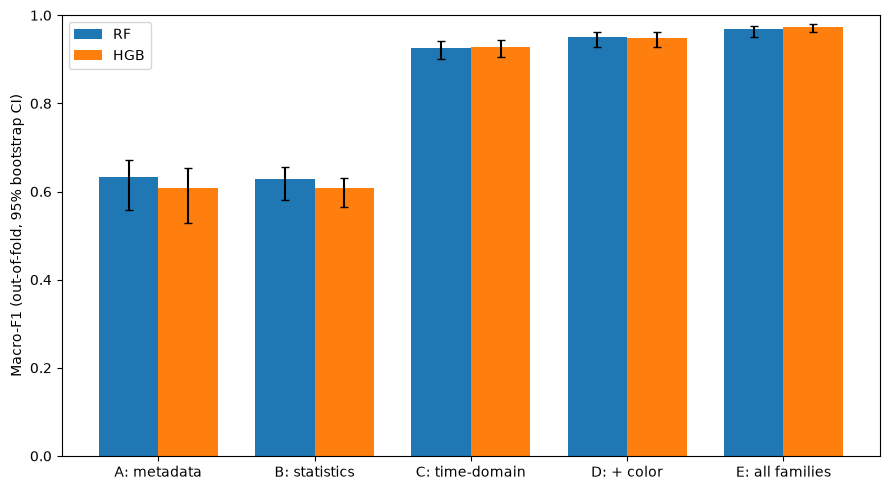

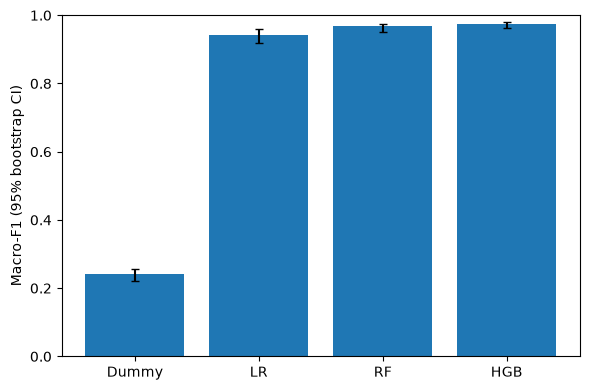

,model,dropped,macro_f1,ci_lo,ci_hi,delta_vs_full,delta_lo,delta_hi
0,RF,magnitude_std,0.9688,0.9540,0.9764,0.0010,-0.0010,0.0043
1,RF,amplitude,0.9682,0.9521,0.9761,0.0004,-0.0022,0.0036
2,RF,fourier_amp,0.9681,0.9525,0.9758,0.0003,-0.0016,0.0032
3,RF,color,0.9660,0.9509,0.9739,-0.0018,-0.0062,0.0034
4,RF,brightness_noise,0.9663,0.9497,0.9733,-0.0015,-0.0062,0.0031
5,RF,timescale,0.9641,0.9487,0.9732,-0.0037,-0.0117,0.0066
6,HGB,magnitude_std,0.9738,0.9613,0.9805,0.0001,-0.0007,0.0007
7,HGB,amplitude,0.9739,0.9610,0.9805,0.0002,-0.0012,0.0010
8,HGB,fourier_amp,0.9733,0.9606,0.9799,-0.0004,-0.0018,0.0004
9,HGB,color,0.9705,0.9587,0.9776,-0.0032,-0.0064,0.0009


In [16]:
PLOT_SETS = ABLATION + ["full"]
labels = ["A: metadata", "B: statistics", "C: time-domain", "D: + color", "E: all families"]
abl = metrics_ci.loc[metrics_ci["feature_set"].isin(PLOT_SETS)]

fig, ax = plt.subplots(figsize=(9, 5))
width = 0.38
for k, name in enumerate(["RF", "HGB"]):
    part = abl.loc[abl["model"].eq(name)].set_index("feature_set").loc[PLOT_SETS]
    ax.bar(np.arange(len(PLOT_SETS)) + (k - 0.5) * width, part["macro_f1"], width, label=name,
           yerr=[(part["macro_f1"] - part["macro_f1_lo"]).to_numpy(),
                 (part["macro_f1_hi"] - part["macro_f1"]).to_numpy()], capsize=3)
ax.set_xticks(range(len(PLOT_SETS)), labels)
ax.set(ylabel="Macro-F1 (out-of-fold, 95% bootstrap CI)", ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_ROOT / "ablation.png", dpi=160, bbox_inches="tight")
plt.show()

order = ["Dummy", "LR", "RF", "HGB"]
comp = metrics_ci.loc[metrics_ci["feature_set"].eq("full") & metrics_ci["model"].isin(order)].set_index("model").loc[order]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(order, comp["macro_f1"],
       yerr=[(comp["macro_f1"] - comp["macro_f1_lo"]).to_numpy(),
             (comp["macro_f1_hi"] - comp["macro_f1"]).to_numpy()], capsize=3)
ax.set(ylabel="Macro-F1 (95% bootstrap CI)", ylim=(0, 1))
fig.tight_layout()
fig.savefig(PLOT_ROOT / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

base = metrics_ci.set_index(["model", "feature_set"])
redundancy = pd.DataFrame([{
    "model": n, "dropped": v.removeprefix("drop_"),
    "macro_f1": base.loc[(n, v), "macro_f1"],
    "ci_lo": base.loc[(n, v), "macro_f1_lo"], "ci_hi": base.loc[(n, v), "macro_f1_hi"],
    "delta_vs_full": PAIRED[((n, "full"), (n, v))]["macro_f1_delta"],
    "delta_lo": PAIRED[((n, "full"), (n, v))]["macro_f1_lo"],
    "delta_hi": PAIRED[((n, "full"), (n, v))]["macro_f1_hi"],
} for n in ["RF", "HGB"] for v in REDUNDANCY + FAMILY_DROPS])
redundancy.to_csv(EXTRA_ROOT / "redundancy.csv", index=False)
display(redundancy.round(4))

## Robustness

In [17]:
stars["n_obs_bin"] = pd.qcut(stars["n_epochs"], 3, labels=["low", "medium", "high"])
stars["g_mag_bin"] = pd.qcut(stars["g_mean_magnitude"], 3, labels=["bright", "middle", "faint"])

SUBSETS = (
    [("n_obs_bin", level, stars["n_obs_bin"].eq(level).to_numpy()) for level in stars["n_obs_bin"].cat.categories]
    + [("g_mag_bin", level, stars["g_mag_bin"].eq(level).to_numpy()) for level in stars["g_mag_bin"].cat.categories]
    + [
        ("label_cohort", "general_class_agrees", stars["matches_general_class"].to_numpy()),
        ("label_cohort", "score>=0.5", (stars["best_class_score"] >= 0.5).to_numpy()),
        ("label_cohort", "score>=0.9", (stars["best_class_score"] >= 0.9).to_numpy()),
    ]
)

robust_rows, class_rows = [], []
for name in ["RF", "HGB"]:
    for variant in ["full", "C_timedomain", "D_full"]:
        for bin_name, level, mask in SUBSETS:
            counts = {f"n_{c}": int((mask & (truth_all == CLASS_INDEX[c])).sum()) for c in CLASSES}
            robust_rows.append({
                "model": name, "feature_set": variant, "bin": bin_name, "level": str(level),
                **counts, "small_class": min(counts.values()) < MIN_CELL,
                **bootstrap_metrics(name, variant, mask),
            })
            for c in CLASSES:
                chosen = mask & (truth_all == CLASS_INDEX[c])
                class_rows.append({
                    "model": name, "feature_set": variant, "bin": bin_name, "level": str(level),
                    "class_name": c, "n_stars": int(chosen.sum()),
                    "recall": (PRED[(name, variant)][:, chosen] == CLASS_INDEX[c]).mean() if chosen.any() else np.nan,
                })

robustness = pd.DataFrame(robust_rows)
robustness_class = pd.DataFrame(class_rows)
robustness.to_csv(EXTRA_ROOT / "robustness.csv", index=False)
robustness_class.to_csv(EXTRA_ROOT / "robustness_class.csv", index=False)
display(robustness.round(4))
display(robustness_class.loc[robustness_class["feature_set"].eq("full")].round(3))

,model,feature_set,bin,level,n_RR Lyrae,n_Cepheid,n_Eclipsing Binary,n_Long-Period Variable,small_class,n_stars,accuracy,accuracy_lo,accuracy_hi,balanced_accuracy,balanced_accuracy_lo,balanced_accuracy_hi,macro_f1,macro_f1_lo,macro_f1_hi
0,RF,full,n_obs_bin,low,227,165,194,129,False,715,0.9684,0.9536,0.9818,0.9705,0.9585,0.9841,0.9709,0.9384,0.9817
1,RF,full,n_obs_bin,medium,126,190,122,173,False,611,0.9712,0.9420,0.9859,0.9697,0.9518,0.9830,0.9687,0.9240,0.9813
2,RF,full,n_obs_bin,high,125,145,184,198,False,652,0.9647,0.9433,0.9773,0.9599,0.9447,0.9740,0.9614,0.9188,0.9732
3,RF,full,g_mag_bin,bright,47,205,73,335,False,660,0.9715,0.9543,0.9834,0.9547,0.9330,0.9751,0.9533,0.9213,0.9713
4,RF,full,g_mag_bin,middle,145,258,100,156,False,659,0.9605,0.9229,0.9795,0.9615,0.9422,0.9751,0.9570,0.9021,0.9722
5,RF,full,g_mag_bin,faint,286,37,327,9,True,659,0.9721,0.9529,0.9854,0.9349,0.8880,0.9715,0.9545,0.9171,0.9782
6,RF,full,label_cohort,general_class_agrees,477,499,500,500,False,1976,0.9685,0.9544,0.9782,0.9683,0.9570,0.9774,0.9683,0.9518,0.9759
7,RF,full,label_cohort,score>=0.5,256,255,325,470,False,1306,0.9960,0.9923,0.9985,0.9952,0.9901,0.9982,0.9953,0.9899,0.9983
8,RF,full,label_cohort,score>=0.9,51,32,87,202,False,372,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
9,RF,C_timedomain,n_obs_bin,low,227,165,194,129,False,715,0.8987,0.8753,0.9253,0.8910,0.8621,0.9199,0.8904,0.8253,0.9064


,model,feature_set,bin,level,class_name,n_stars,recall
0,RF,full,n_obs_bin,low,RR Lyrae,227,0.956
1,RF,full,n_obs_bin,low,Cepheid,165,0.958
2,RF,full,n_obs_bin,low,Eclipsing Binary,194,0.976
3,RF,full,n_obs_bin,low,Long-Period Variable,129,0.992
4,RF,full,n_obs_bin,medium,RR Lyrae,126,0.937
...,...,...,...,...,...,...,...
139,HGB,full,label_cohort,score>=0.5,Long-Period Variable,470,0.995
140,HGB,full,label_cohort,score>=0.9,RR Lyrae,51,1.000
141,HGB,full,label_cohort,score>=0.9,Cepheid,32,1.000
142,HGB,full,label_cohort,score>=0.9,Eclipsing Binary,87,1.000


## Period Status

In [18]:
status_rows, paired_rows = [], []

PERIOD_SETS = ["full", "oracle", "period_free"]

for name in ["RF", "HGB"]:
    for class_name in CLASSES:
        for status in STATUSES:
            part = oof.loc[oof["class_name"].eq(class_name) & oof["period_status"].eq(status)]

            if part.empty:
                continue

            variants = [v for v in PERIOD_SETS if status != "ineligible" or v != "oracle"]

            for variant in variants:
                n, recall, low, high = bootstrap(
                    part, f"correct_{name}_{variant}",
                    seed=SEED + 100 * CLASSES.index(class_name)
                    + 10 * STATUSES.index(status) + PERIOD_SETS.index(variant),
                )
                status_rows.append({
                    "model": name, "class_name": class_name,
                    "period_status": status, "feature_set": variant,
                    "n_stars": n, "recall": recall,
                    "ci_lo": low, "ci_hi": high, "small_cell": n < MIN_CELL,
                })

            pairs = [("full", "period_free")]

            if status != "ineligible":
                pairs += [("full", "oracle"), ("oracle", "period_free")]

            for first, second in pairs:
                n, delta, low, high = bootstrap(
                    part, f"correct_{name}_{first}", f"correct_{name}_{second}",
                    seed=SEED + 100 * CLASSES.index(class_name)
                    + 10 * STATUSES.index(status) + PERIOD_SETS.index(second),
                )
                paired_rows.append({
                    "model": name, "class_name": class_name,
                    "period_status": status,
                    "reference": first, "compared": second,
                    "n_stars": n, "recall_delta": delta,
                    "ci_lo": low, "ci_hi": high, "small_cell": n < MIN_CELL,
                })

status_scores = pd.DataFrame(status_rows)
paired_status = pd.DataFrame(paired_rows)

status_scores.to_csv(EXTRA_ROOT / "status.csv", index=False)
paired_status.to_csv(EXTRA_ROOT / "paired.csv", index=False)

display(status_scores.loc[status_scores["period_status"].isin(["half", "mismatch"])].round(3))
display(paired_status.loc[paired_status["period_status"].isin(["half", "mismatch"])].round(3))

,model,class_name,period_status,feature_set,n_stars,recall,ci_lo,ci_hi,small_cell
3,RF,RR Lyrae,half,full,1,1.000,1.000,1.000,True
4,RF,RR Lyrae,half,oracle,1,0.600,0.600,0.600,True
5,RF,RR Lyrae,half,period_free,1,1.000,1.000,1.000,True
6,RF,RR Lyrae,mismatch,full,85,0.976,0.938,1.000,False
7,RF,RR Lyrae,mismatch,oracle,85,0.979,0.947,1.000,False
8,RF,RR Lyrae,mismatch,period_free,85,0.976,0.932,1.000,False
12,RF,Cepheid,mismatch,full,5,0.800,0.250,1.000,True
13,RF,Cepheid,mismatch,oracle,5,0.800,0.250,1.000,True
14,RF,Cepheid,mismatch,period_free,5,0.800,0.250,1.000,True
18,RF,Eclipsing Binary,half,full,366,0.983,0.977,0.988,False


,model,class_name,period_status,reference,compared,n_stars,recall_delta,ci_lo,ci_hi,small_cell
3,RF,RR Lyrae,half,full,period_free,1,0.000,0.000,0.000,True
4,RF,RR Lyrae,half,full,oracle,1,-0.400,-0.400,-0.400,True
5,RF,RR Lyrae,half,oracle,period_free,1,0.400,0.400,0.400,True
6,RF,RR Lyrae,mismatch,full,period_free,85,0.000,0.000,0.000,False
7,RF,RR Lyrae,mismatch,full,oracle,85,0.002,-0.007,0.015,False
8,RF,RR Lyrae,mismatch,oracle,period_free,85,-0.002,-0.014,0.007,False
12,RF,Cepheid,mismatch,full,period_free,5,0.000,0.000,0.000,True
13,RF,Cepheid,mismatch,full,oracle,5,0.000,0.000,0.000,True
14,RF,Cepheid,mismatch,oracle,period_free,5,0.000,0.000,0.000,True
18,RF,Eclipsing Binary,half,full,period_free,366,-0.044,-0.060,-0.021,False


## Feature Importance

In [19]:
importance_folds = pd.DataFrame(importance_rows)

importance = (
    importance_folds.groupby("feature", as_index=False)
    .agg(
        f1_drop=("macro_f1_drop", "mean"),
        f1_std=("macro_f1_drop", "std"),
    )
    .sort_values("f1_drop", ascending=False)
)

feature_groups = {
    col: name for name, cols in GROUPS.items() for col in cols
}

importance["group"] = importance["feature"].map(feature_groups)

importance_folds.to_csv(EXTRA_ROOT / "importance_folds.csv", index=False)
importance.to_csv(EXTRA_ROOT / "importance.csv", index=False)

display(importance.head(15).round(4))

,feature,f1_drop,f1_std,group
14,magnitude_skew,0.0612,0.0132,shape
3,bp_rp_color,0.0461,0.0087,color
10,log_period,0.0292,0.0112,period
18,power,0.0286,0.0115,period
20,sf_ratio,0.0159,0.0098,timescale
22,stetson_j,0.0070,0.0054,timescale
21,sf_short,0.0026,0.0078,timescale
6,fourier_amp,0.0026,0.0021,period
7,fourier_ratio,0.0024,0.0021,period
11,magnitude_kurt,0.0022,0.0013,shape


In [20]:
family_importance = (
    pd.DataFrame(family_rows).groupby("family")["macro_f1_drop"]
    .agg(f1_drop="mean", f1_std="std").sort_values("f1_drop", ascending=False)
)
family_importance.to_csv(EXTRA_ROOT / "importance_family.csv")
display(family_importance.round(4))

,f1_drop,f1_std
family,,
timescale,0.3744,0.0182
period,0.1359,0.0218
shape,0.1232,0.0127
color,0.0514,0.0116
brightness_noise,0.0119,0.0070


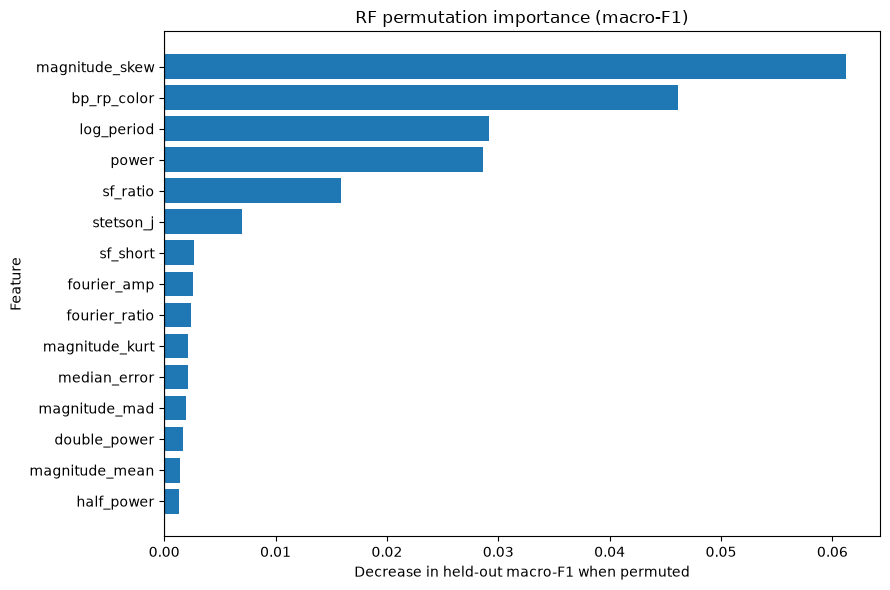

In [21]:
top = importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(top["feature"], top["f1_drop"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    xlabel="Decrease in held-out macro-F1 when permuted",
    ylabel="Feature",
    title=f"{PRIMARY} permutation importance (macro-F1)",
)

fig.tight_layout()
fig.savefig(PLOT_ROOT / "importance.png", dpi=160, bbox_inches="tight")
plt.show()

## Confusion Matrix

,RR Lyrae,Cepheid,Eclipsing Binary,Long-Period Variable
RR Lyrae,455,7,16,0
Cepheid,14,472,7,7
Eclipsing Binary,4,4,490,2
Long-Period Variable,0,1,0,499


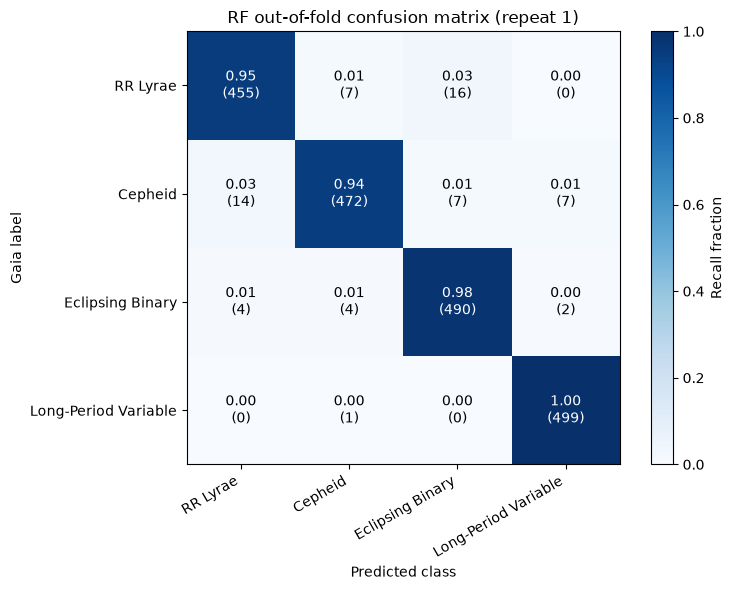

In [22]:
first = oof.loc[oof["repeat"].eq(1)]
pred_col = f"pred_{PRIMARY}_full"

cm = confusion_matrix(first["class_name"], first[pred_col], labels=CLASSES)
rates = cm / cm.sum(axis=1, keepdims=True)

display(pd.DataFrame(cm, index=CLASSES, columns=CLASSES))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(rates, vmin=0, vmax=1, cmap="Blues")

ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(
    xlabel="Predicted class",
    ylabel="Gaia label",
    title=f"{PRIMARY} out-of-fold confusion matrix (repeat 1)",
)

for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(
            j, i, f"{rates[i, j]:.2f}\n({cm[i, j]})",
            ha="center", va="center",
            color="white" if rates[i, j] > 0.5 else "black",
        )

fig.colorbar(image, ax=ax, label="Recall fraction")
fig.tight_layout()
fig.savefig(PLOT_ROOT / "confusion.png", dpi=160, bbox_inches="tight")
plt.show()

In [23]:
p, r, f, s = precision_recall_fscore_support(
    oof["class_name"], oof[f"pred_{PRIMARY}_full"], labels=CLASSES, zero_division=0
)
per_class = pd.DataFrame({
    "class_name": CLASSES, "precision": p, "recall": r, "f1": f, "n_per_repeat": s // REPEATS,
})
per_class.to_csv(EXTRA_ROOT / "per_class.csv", index=False)
display(per_class.round(4))

,class_name,precision,recall,f1,n_per_repeat
0,RR Lyrae,0.9591,0.9515,0.9553,478
1,Cepheid,0.9747,0.9416,0.9579,500
2,Eclipsing Binary,0.9544,0.9804,0.9672,500
3,Long-Period Variable,0.9838,0.9980,0.9909,500


,class_name,period_status,gaia_period,n_epochs,bp_rp_color,eligible,correct,predicted
source_id,,,,,,,,
2073071522843025664,Cepheid,exact,0.336,52,0.774,True,0.4,Cepheid
4053752797328611840,Cepheid,exact,0.392,29,2.314,True,0.0,Eclipsing Binary
4149825546359977472,Cepheid,exact,0.328,44,0.929,True,0.0,Eclipsing Binary
4167610765375937024,Cepheid,exact,0.726,54,1.609,True,0.0,Eclipsing Binary
5356903491857522304,Cepheid,mismatch,5.883,58,1.895,True,0.0,Eclipsing Binary
5933434308006613760,Cepheid,exact,0.265,110,1.048,True,0.0,Eclipsing Binary
5941658375763435648,Cepheid,exact,0.254,76,1.866,True,0.0,Eclipsing Binary
6057642185223184384,Cepheid,exact,0.213,53,1.881,True,0.0,Eclipsing Binary
4040934347214861440,Cepheid,exact,11.666,51,2.421,True,0.4,Long-Period Variable


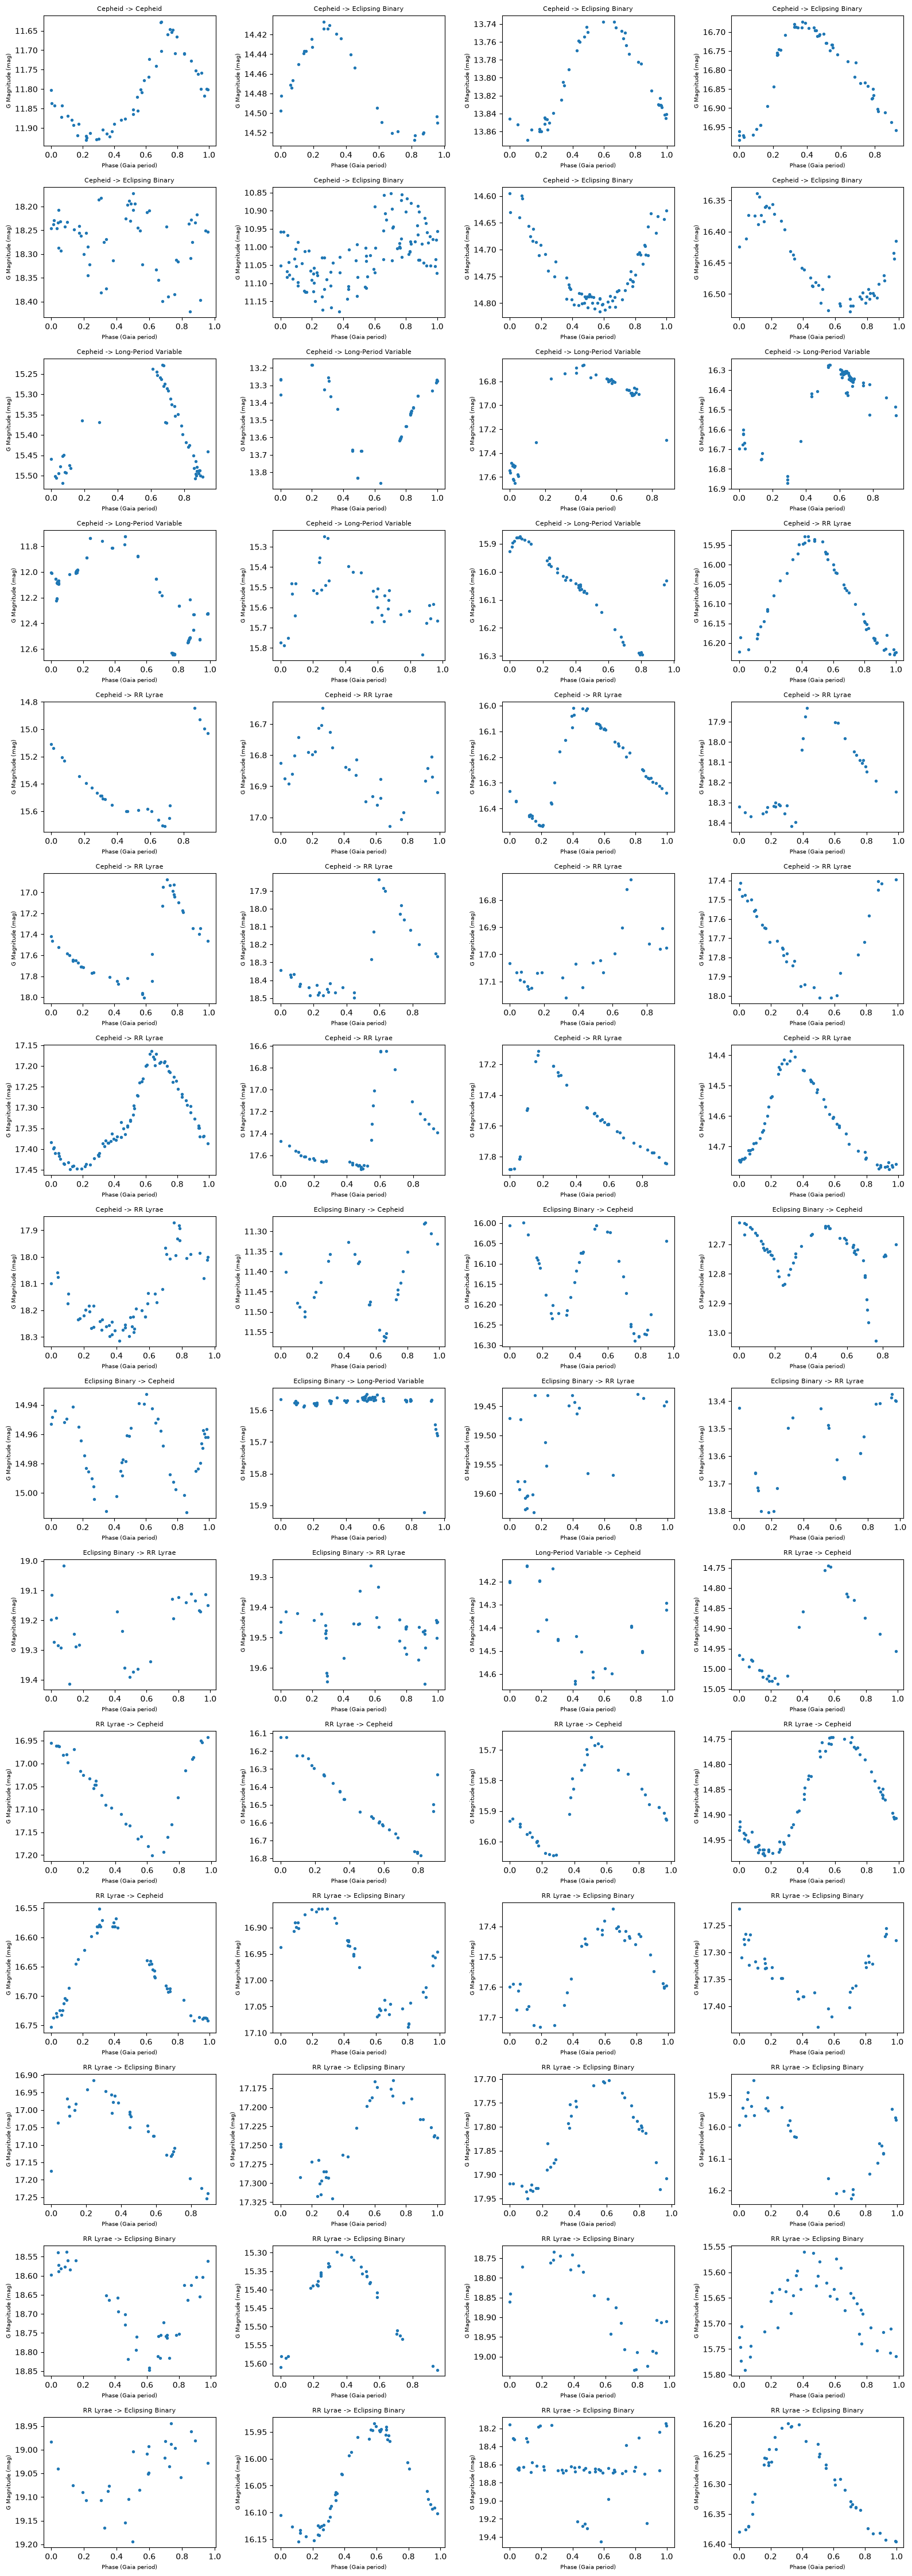

In [24]:
photometry = pd.read_csv(CLEAN_FILE, usecols=["source_id", "g_transit_time", "g_transit_mag"])

vote = oof.groupby("source_id").agg(
    correct=(f"correct_{PRIMARY}_full", "mean"),
    predicted=(f"pred_{PRIMARY}_full", lambda s: s.mode().iloc[0]),
)
errors = (
    stars.set_index("source_id")[["class_name", "period_status", "gaia_period", "n_epochs", "bp_rp_color", "eligible"]]
    .join(vote)
)
errors = errors.loc[errors["correct"] < 0.5].sort_values(["class_name", "predicted"])
errors.to_csv(EXTRA_ROOT / "misclassified.csv")
display(errors.round(3))

ncols = 4
nrows = int(np.ceil(len(errors) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows), squeeze=False)

for ax in axes.ravel():
    ax.set_axis_off()

for ax, (source_id, row) in zip(axes.ravel(), errors.iterrows()):
    curve = photometry.loc[photometry["source_id"].eq(source_id)]
    time = curve["g_transit_time"] - curve["g_transit_time"].min()

    ax.set_axis_on()
    if row["eligible"]:
        ax.scatter((time / row["gaia_period"]) % 1, curve["g_transit_mag"], s=8)
        ax.set_xlabel("Phase (Gaia period)", fontsize=7)
    else:
        ax.scatter(time, curve["g_transit_mag"], s=8)
        ax.set_xlabel("Days since first epoch", fontsize=7)
    ax.invert_yaxis()
    ax.set_ylabel("G Magnitude (mag)", fontsize=7)
    ax.set_title(f"{row['class_name']} -> {row['predicted']}", fontsize=8)

fig.tight_layout()
fig.savefig(PLOT_ROOT / "misclassified_lightcurves.png", dpi=160, bbox_inches="tight")
plt.show()

## Final Model

In [25]:
final_model = make_model(PRIMARY, "full")
final_model.fit(stars[BASE_FEATURES], y)

joblib.dump(final_model, MODEL_FILE)

metadata = {
    "model": PRIMARY,
    "sources": len(stars),
    "folds": FOLDS,
    "repeats": REPEATS,
    "seed": SEED,
    "bootstrap_replicates": BOOTSTRAPS,
    "hyperparameters_tuned": False,
    "classes": CLASSES,
    "features": BASE_FEATURES,
    "groups": GROUPS,
    "sky_group": "HEALPix nside=16 cells",
}

with (EXTRA_ROOT / "metadata.json").open("w") as file:
    json.dump(metadata, file, indent=2)

print("Model:", MODEL_FILE)
print("CV scores:", CV_FILE)
print("CV ranking:", RANK_FILE)
print("OOF predictions:", PRED_FILE)
print("Results:", EXTRA_ROOT)
print("Figures:", PLOT_ROOT)

Model: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/model.joblib
CV scores: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/cv.csv
CV ranking: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/rank.csv
OOF predictions: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/pred.csv
Results: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/gaia_classification
Figures: /Users/Sumaitat/Documents/Coding/gaia-varstars/reports/figures/gaia_classification
